# 24. 처음부터 만드는 개념 학습기 (C 경로 1–3단계)

지금까지 MK1의 생각 위성(격자 탐색기)은 **사람이 손으로 만든 기본 동작 약 90개** 안에서만 생각했어. ConceptARC 최소 과제 16개념 중 12개는 그 동작으로 표현조차 안 됐지. 그래서 "새 개념을 스스로 얻는 부품"을 **처음부터** 만들기로 했어(C 경로).

| 단계 | 무엇 | 관문 | 결과 |
|---|---|---|---|
| 1 | 합성 과제 생성기 (개념 가족 28개) | 탐색기가 푸는 비율이 가족마다 다양 | **통과** |
| 2 | 작은 개념 학습기 (2.68M, 처음부터) | 안 본 가족에서 미리 학습 > 처음부터, +0.10 | **통과 (+0.300)** |
| 3 | 학습기 + 검증, 탐색기 옆에 | ARC에서 C > S, 그리고 답할 때 정답률 ≥ 0.90 | **실패 (0.891)** |

설계와 판정 규칙: `design/build-from-scratch-2026-10-10.md` 9–13절(사전 등록은 학습 전에 커밋). 여기선 저장된 결과만 읽어서 그려(모델 안 돌림).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from cognitive_lab import summary_concepts as S
from cognitive_lab import viz as V
V.setup()
ARC_CMAP = ListedColormap(["#000000", "#0074D9", "#FF4136", "#2ECC40", "#FFDC00", "#AAAAAA", "#F012BE", "#FF851B",
                           "#7FDBFF", "#870C25"])
gen, ex, logs, s2, s3 = S.generator_check(), S.examples(), S.pretrain_logs(), S.step2(), S.step3()
print("2단계 판정:", {n: tuple(round(x, 3) for x in v) for n, v in s2["verdict"].items()})
for h in ("tune", "check"):
    d = s3[h]
    print(f"3단계 {h}: S {d['S']:.3f}  C {d['C']:.3f}  정답률 C {d['precision_C']:.3f}  "
          f"학습기 시도 {d['learner_tried']} -> 검증 통과 {d['learner_passed']} -> 맞음 {d['learner_right']}")

2단계 판정: {8: (0.232, 0.22, 0.244), 32: (0.3, 0.285, 0.315)}
3단계 tune: S 0.185  C 0.216  정답률 C 0.957  학습기 시도 83 -> 검증 통과 8 -> 맞음 7
3단계 check: S 0.175  C 0.205  정답률 C 0.891  학습기 시도 71 -> 검증 통과 11 -> 맞음 6


## 1. 생성기: 핵심 지식 사전에서 개념 가족 28개

Chollet의 핵심 지식 사전(물체성, 기하·위상, 수 세기, 목표 지향)과 비교(같다/다르다)에서 출발했어. 가족마다 매개변수(색, 방향, 크기, 개수)가 과제마다 바뀌어서, **예시에서 규칙을 읽어 내야** 풀 수 있어. 과제는 무한히 뽑을 수 있어.

정직한 메모: ConceptARC 과제를 보고 만들지 않았어. 하지만 개념 이름 16개와 최소 과제 16개는 전에 봤으니까 이름이 겹치는 가족이 있어. ConceptARC 본 과제(corpus)는 봉인 그대로야.

아래는 탐색기가 **못 푸는** 가족의 예시야(왼쪽 입력 → 오른쪽 출력).

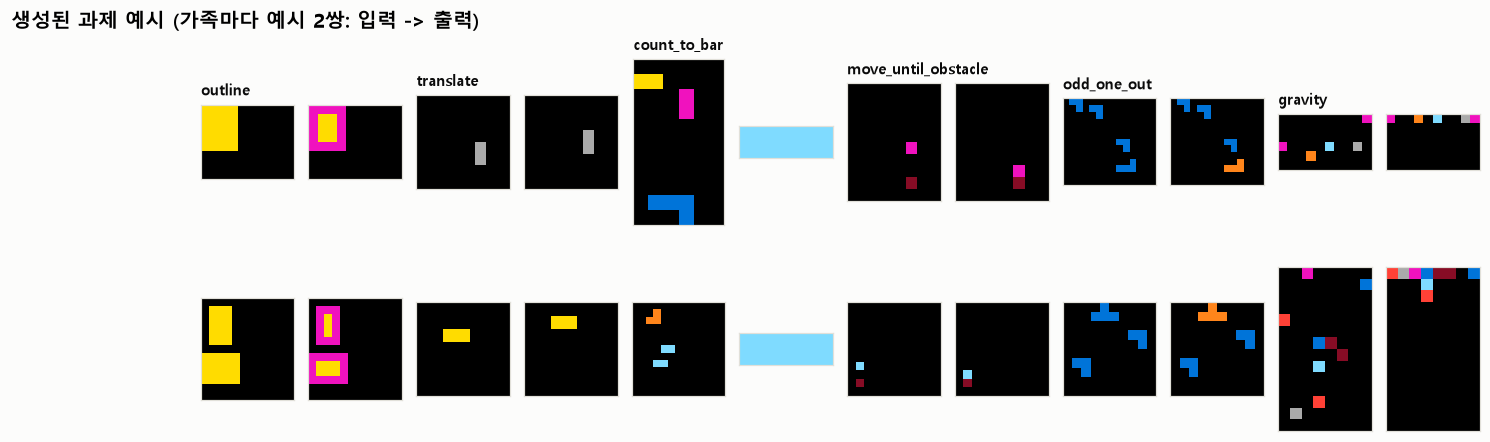

In [2]:
fig, axes = plt.subplots(2, len(ex) * 2, figsize=(15, 4.4), gridspec_kw={"wspace": 0.15, "hspace": 0.25})
for j, e in enumerate(ex):
    for i, (a, b) in enumerate(e["pairs"]):
        for k, g in enumerate((a, b)):
            ax = axes[i, 2 * j + k]
            ax.imshow(np.array(g), cmap=ARC_CMAP, vmin=0, vmax=9)
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            for s in ax.spines.values():
                s.set_visible(True); s.set_color(V.GRID)
    axes[0, 2 * j].set_title(e["family"], fontsize=9.5, loc="left")
fig.suptitle("생성된 과제 예시 (가족마다 예시 2쌍: 입력 -> 출력)", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.show()

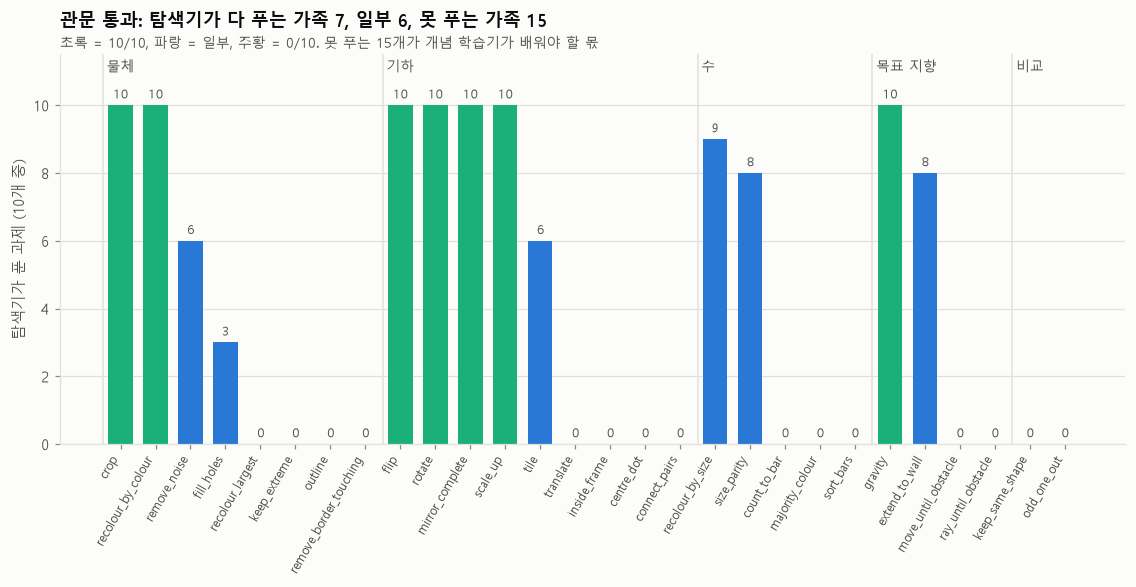

In [3]:
order = sorted(gen, key=lambda r: (list(S.GROUP_NAMES).index(r["group"]), -r["search"]))
fig, ax = plt.subplots(figsize=(12.5, 4.6))
colors = [V.AQUA if r["search"] == 10 else (V.BLUE if r["search"] > 0 else V.ORANGE) for r in order]
ax.bar(range(len(order)), [r["search"] for r in order], color=colors, width=0.7)
for i, r in enumerate(order):
    ax.text(i, r["search"] + 0.2, str(r["search"]), ha="center", fontsize=8, color=V.TEXT_SECONDARY)
ax.set_xticks(range(len(order)), [r["family"] for r in order], rotation=60, ha="right", fontsize=8)
ax.set_ylabel("탐색기가 푼 과제 (10개 중)"); ax.set_ylim(0, 11.5); ax.grid(axis="x", visible=False)
prev = None
for i, r in enumerate(order):
    if r["group"] != prev:
        ax.axvline(i - 0.5, color=V.GRID, lw=1)
        ax.text(i - 0.4, 11.0, S.GROUP_NAMES[r["group"]], fontsize=9, color=V.TEXT_SECONDARY)
        prev = r["group"]
ax.set_title("관문 통과: 탐색기가 다 푸는 가족 7, 일부 6, 못 푸는 가족 15", pad=18)
V.note(ax, "초록 = 10/10, 파랑 = 일부, 주황 = 0/10. 못 푸는 15개가 개념 학습기가 배워야 할 몫")
plt.show()

## 2. 작은 개념 학습기: 처음부터, 그리고 배우는 법 배우기

**구조**: 격자 8장(예시 3쌍 + 시험 입력 + 시험 출력 자리)을 14×14로 채워 1,568개 토큰으로 넣는 작은 트랜스포머(2.68M 파라미터). 시험 출력 196칸을 한 번에 예측해. 손으로 만든 동작은 하나도 없어. 개념에 대해 아는 건 전부 과제에서 배운 거야.

**사전 등록한 질문**: 다른 가족으로 미리 학습한 모델이, **처음 보는 가족**을 같은 크기의 처음부터 모델보다 적은 예시로 더 정확히 배우는가?
- 가족 나누기(시드 고정): train 17 / dev 4(적응 방법 고르기만) / **test 7(판정 한 번)**
- 기준: N=32(새 가족 과제 32개로 적응)에서 차이 ≥ +0.10, 95% 구간 하한 > 0

미리 학습은 train 17가족으로 20,000스텝(73분)을 했어. 학습 가족의 새 과제를 **예시만 보고** 0.746 맞혀.

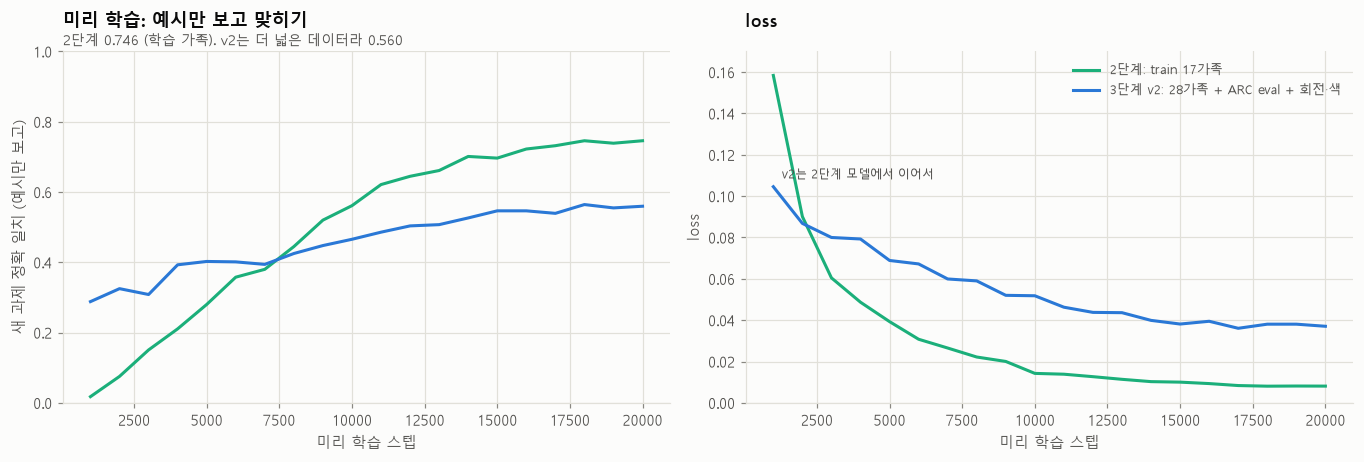

In [4]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(12.5, 4.3))
for key, color, label in (("step2", V.AQUA, "2단계: train 17가족"), ("step3", V.BLUE, "3단계 v2: 28가족 + ARC eval + 회전·색")):
    L = logs[key]
    steps = [r["step"] for r in L]
    acc = [r.get("val_exact", r.get("val_exact_families")) for r in L]
    ax.plot(steps, acc, color=color, label=label)
    bx.plot(steps, [r["loss"] for r in L], color=color, label=label)
ax.set_xlabel("미리 학습 스텝"); ax.set_ylabel("새 과제 정확 일치 (예시만 보고)"); ax.set_ylim(0, 1)
ax.set_title("미리 학습: 예시만 보고 맞히기", pad=16); V.note(ax, "2단계 0.746 (학습 가족). v2는 더 넓은 데이터라 0.560")
bx.set_xlabel("미리 학습 스텝"); bx.set_ylabel("loss"); bx.set_ylim(0, 0.17)
bx.set_title("loss", pad=16); bx.legend(fontsize=8.5)
v2 = logs["step3"]; bx.text(v2[0]["step"] + 300, v2[0]["loss"] + 0.004, "v2는 2단계 모델에서 이어서", fontsize=8, color=V.TEXT_SECONDARY)
plt.tight_layout(); plt.show()

### 적응 방법 고르기 (dev 가족만): 상대에게 가장 유리하게

처음엔 적응 300스텝으로 했는데, 그러면 **처음부터 모델이 덜 학습돼서** 차이가 부풀어(+0.268). 그래서 원칙을 정했어: **상대(처음부터)가 가장 잘하는 방법**을 고른다. 1500스텝에서 처음부터 쪽이 거의 다 올라왔고(3000스텝과 같음), 그걸로 얼렸어.

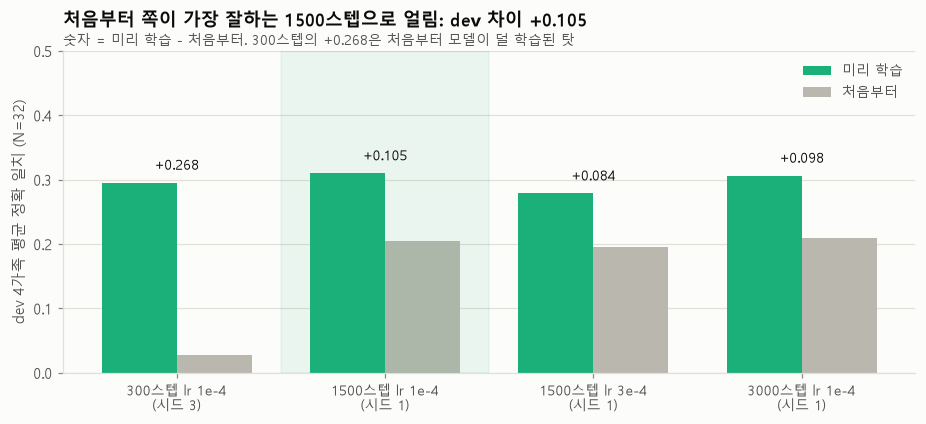

In [5]:
R = s2["recipes"]
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(R)); w = 0.36
ax.bar(x - w / 2, [r["pretrained"] for r in R], w, color=V.AQUA, label="미리 학습")
ax.bar(x + w / 2, [r["scratch"] for r in R], w, color=V.NEUTRAL, label="처음부터")
for i, r in enumerate(R):
    d, lo, hi = r["diff"]
    ax.text(i, max(r["pretrained"], r["scratch"]) + 0.02, f"{d:+.3f}", ha="center", fontsize=9, color=V.TEXT)
ax.set_xticks(x, [f"{r['recipe']}\n(시드 {r['runs']})" for r in R], fontsize=9)
ax.set_ylabel("dev 4가족 평균 정확 일치 (N=32)"); ax.set_ylim(0, 0.5); ax.grid(axis="x", visible=False)
ax.legend(fontsize=9, loc="upper right")
ax.axvspan(0.5, 1.5, color=V.AQUA, alpha=0.08)
ax.set_title("처음부터 쪽이 가장 잘하는 1500스텝으로 얼림: dev 차이 +0.105", pad=16)
V.note(ax, "숫자 = 미리 학습 - 처음부터. 300스텝의 +0.268은 처음부터 모델이 덜 학습된 탓")
plt.show()

### 판정: test 가족 7개 (한 번)

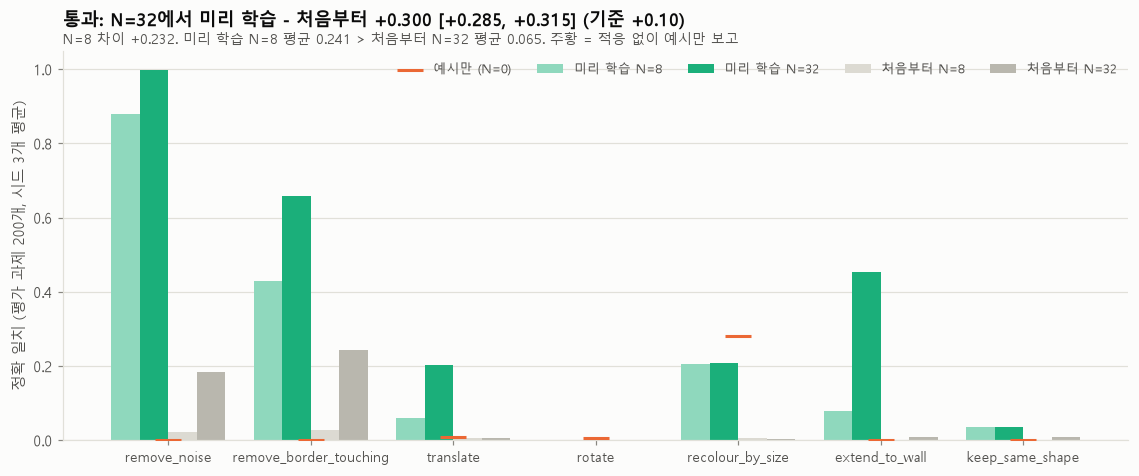

In [6]:
T = s2["test"]; fams = list(T)
fig, ax = plt.subplots(figsize=(12.5, 4.6))
x = np.arange(len(fams)); w = 0.2
bars = [("pretrained_n8", "미리 학습 N=8", "#8fd8bd"), ("pretrained_n32", "미리 학습 N=32", V.AQUA),
        ("scratch_n8", "처음부터 N=8", "#dcdad2"), ("scratch_n32", "처음부터 N=32", V.NEUTRAL)]
for k, (key, label, color) in enumerate(bars):
    ax.bar(x + (k - 1.5) * w, [T[f][key] for f in fams], w, color=color, label=label)
ax.scatter(x, [T[f]["zero_shot"] for f in fams], marker="_", s=300, color=V.ORANGE, zorder=3, label="예시만 (N=0)")
ax.set_xticks(x, fams, fontsize=9); ax.set_ylim(0, 1.05); ax.grid(axis="x", visible=False)
ax.set_ylabel("정확 일치 (평가 과제 200개, 시드 3개 평균)"); ax.legend(fontsize=8.5, ncol=5, loc="upper right")
(d8, l8, h8), (d32, l32, h32) = s2["verdict"][8], s2["verdict"][32]
ax.set_title(f"통과: N=32에서 미리 학습 - 처음부터 {d32:+.3f} [{l32:+.3f}, {h32:+.3f}] (기준 +0.10)", pad=16)
V.note(ax, f"N=8 차이 {d8:+.3f}. 미리 학습 N=8 평균 0.241 > 처음부터 N=32 평균 0.065. 주황 = 적응 없이 예시만 보고")
plt.show()

**읽는 법**
- **배우는 법을 배웠다**: 처음 보는 가족에서, 미리 학습한 모델이 과제 8개로 낸 정확도가 처음부터 모델이 32개로 낸 것보다 높아. 7개 중 6개 가족에서 앞서고, rotate는 둘 다 0이야.
- **하지만 예시만 보고 새 개념을 바로 맞히진 못해**(주황 선, 평균 0.042). 학습 가족은 예시만 보고 0.746을 맞히는데, 새 가족은 몇 개 과제로 짧게 학습해야 얻어. 지금 얻은 건 **"빨리 배우는 바탕"**이지, 사람처럼 예시 3개 보고 "아 이거구나" 하는 능력은 아니야.
- recolour_by_size는 적응 뒤(0.21)가 적응 전(0.28)보다 낮아. 적응이 해칠 때가 있어.
- 가족이 7개뿐이라 "다른 가족으로의 일반화"는 그만큼만 말할 수 있어.

## 3. 탐색기 옆에 붙이기: 사람이 만든 ARC 과제

**설계**: 탐색기가 답을 못 낸 과제에서만 학습기가 나서. 원칙은 MK1 그대로야: "확인할 수 있을 때만 답한다".
1. 예시 하나를 **완전히 빼 두고** 나머지로 짧게 적응(300스텝, 회전·뒤집기·색 바꾸기)
2. 빼 둔 예시를 여러 변환으로 예측해서 다수결 → **정확히 맞고 동의 비율 ≥ 0.3일 때만** 시험에 답해

데이터 역할: ARC-AGI-1 training을 반으로 나눴어(조정용 200, 확인용 200, 한 번). evaluation은 이미 MK1 v2 최종 시험으로 썼으니 미리 학습 데이터로 썼어. 학습기 v2는 14×14까지만 받아서 ARC training 400개 중 247개만 볼 수 있어.

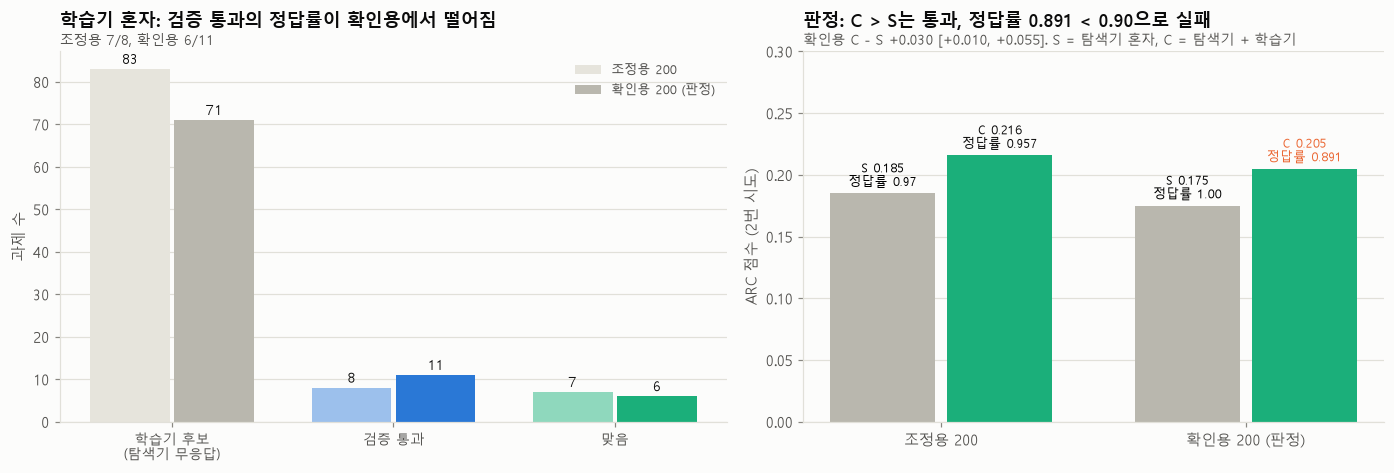

In [7]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})
halves = (("tune", "조정용 200"), ("check", "확인용 200 (판정)"))
stages = ["학습기 후보\n(탐색기 무응답)", "검증 통과", "맞음"]
for k, (h, label) in enumerate(halves):
    d = s3[h]
    vals = [d["learner_tried"], d["learner_passed"], d["learner_right"]]
    xs = np.arange(3) + (k - 0.5) * 0.38
    ax.bar(xs, vals, 0.36, color=[V.NEUTRAL, V.BLUE, V.AQUA] if k else ["#e6e4dc", "#9cc0ec", "#8fd8bd"], label=label)
    for xx, v in zip(xs, vals):
        ax.text(xx, v + 1.2, str(v), ha="center", fontsize=9, color=V.TEXT)
ax.set_xticks(range(3), stages, fontsize=9); ax.grid(axis="x", visible=False); ax.set_ylabel("과제 수")
ax.legend(fontsize=8.5); ax.set_title("학습기 혼자: 검증 통과의 정답률이 확인용에서 떨어짐", pad=16)
V.note(ax, f"조정용 {s3['tune']['learner_right']}/{s3['tune']['learner_passed']}, 확인용 {s3['check']['learner_right']}/{s3['check']['learner_passed']}")

for k, (h, label) in enumerate(halves):
    d = s3[h]
    bx.bar(k * 2.6, d["S"], 0.9, color=V.NEUTRAL); bx.bar(k * 2.6 + 1, d["C"], 0.9, color=V.AQUA)
    bx.text(k * 2.6, d["S"] + 0.006, f"S {d['S']:.3f}\n정답률 {d['precision_S']:.2f}", ha="center", fontsize=8.5)
    bx.text(k * 2.6 + 1, d["C"] + 0.006, f"C {d['C']:.3f}\n정답률 {d['precision_C']:.3f}", ha="center", fontsize=8.5,
            color=V.ORANGE if d["precision_C"] < 0.9 else V.TEXT)
bx.set_xticks([0.5, 3.1], [l for _, l in halves]); bx.set_ylim(0, 0.3); bx.grid(axis="x", visible=False)
bx.set_ylabel("ARC 점수 (2번 시도)")
dd = s3["check"]["diff"]
bx.set_title("판정: C > S는 통과, 정답률 0.891 < 0.90으로 실패", pad=16)
V.note(bx, f"확인용 C - S {dd[0]:+.3f} [{dd[1]:+.3f}, {dd[2]:+.3f}]. S = 탐색기 혼자, C = 탐색기 + 학습기")
plt.tight_layout(); plt.show()

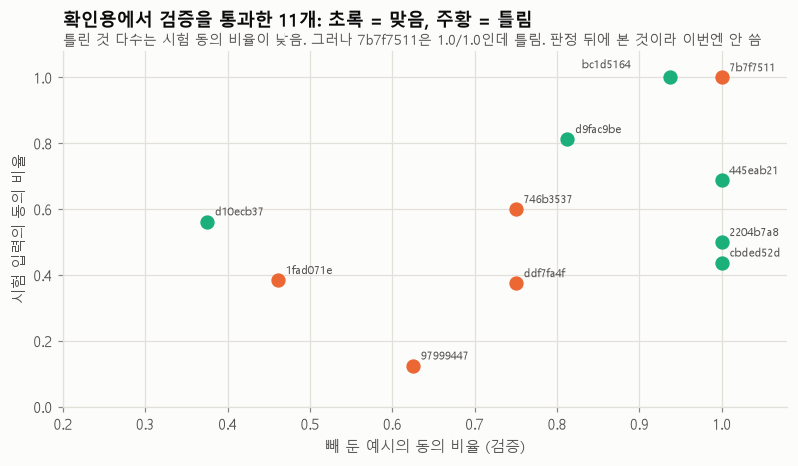

In [8]:
ps = s3["check"]["passed_share"]
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for name, cs, ts, sc in ps:
    ax.scatter(cs, ts, s=70, color=V.AQUA if sc > 0 else V.ORANGE, zorder=3)
    off = (-58, 6) if name == "bc1d5164" else (5, 4)
    ax.annotate(name, (cs, ts), textcoords="offset points", xytext=off, fontsize=7.5, color=V.TEXT_SECONDARY)
ax.set_xlabel("빼 둔 예시의 동의 비율 (검증)"); ax.set_ylabel("시험 입력의 동의 비율")
ax.set_xlim(0.2, 1.08); ax.set_ylim(0, 1.08)
ax.set_title("확인용에서 검증을 통과한 11개: 초록 = 맞음, 주황 = 틀림", pad=16)
V.note(ax, "틀린 것 다수는 시험 동의 비율이 낮음. 그러나 7b7f7511은 1.0/1.0인데 틀림. 판정 뒤에 본 것이라 이번엔 안 씀")
plt.show()

**읽는 법**
- **진짜 이득은 있어**: 처음부터 학습한 2.68M 모델이 탐색기가 손도 못 댄 ARC 과제를 확인용 200개 중 **6개 새로** 풀었어(C − S +0.030, 구간 > 0).
- **검증이 약했어**: 빼 둔 예시 하나는 우연히 맞을 수 있어(예시 3개짜리면 2개로 적응). 모든 변환이 같은 틀린 답에 동의하기도 해(7b7f7511). 그래서 "답할 때는 거의 안 틀린다"(≥ 0.90)를 0.009 차이로 못 지켰어.
- 시험 동의 비율을 기준에 넣었으면 걸렀을 거야. 하지만 **판정을 보고 나서 기준을 고치는 건 반칙**이라 이번 결과는 실패로 기록해. ARC training의 두 절반을 다 썼으니까, 고친 검증은 새 개발 시험에서 다시 판정해야 해.

## 4. 지금 MK1은 어디까지 왔나

AGI 특성별로 봉인 시험 결과를 모았어. 상대는 Gemma 4 E4B 단일 모델(개념 학습기 줄만 상대가 다름).

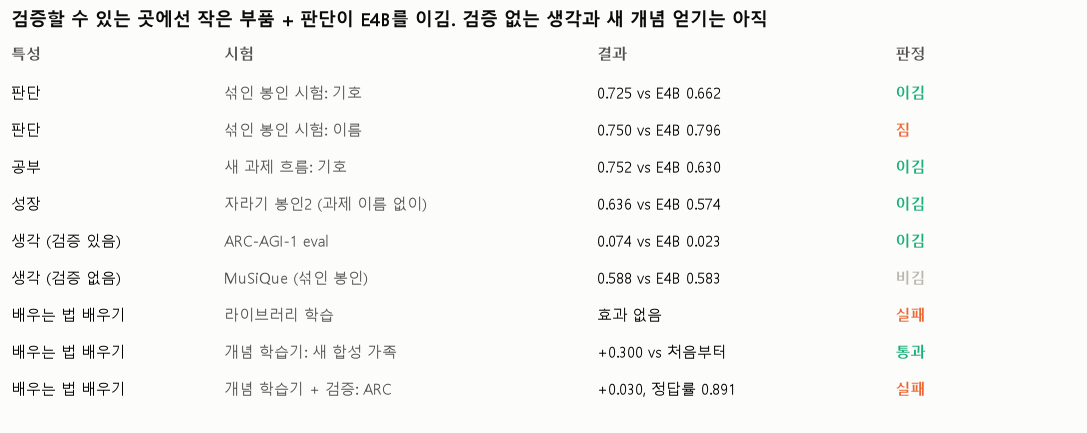

In [9]:
fig, ax = plt.subplots(figsize=(12.5, 4.6)); ax.axis("off")
col = {"이김": V.AQUA, "통과": V.AQUA, "비김": V.NEUTRAL, "짐": V.ORANGE, "실패": V.ORANGE}
head = ["특성", "시험", "결과", "판정"]; xs = [0.0, 0.2, 0.55, 0.83]
for x, h in zip(xs, head):
    ax.text(x, 0.93, h, fontsize=10, fontweight="bold", color=V.TEXT_SECONDARY, transform=ax.transAxes)
for i, (trait, what, res, verdict) in enumerate(S.TRAITS):
    y = 0.83 - i * 0.095
    ax.text(xs[0], y, trait, fontsize=10, transform=ax.transAxes)
    ax.text(xs[1], y, what, fontsize=9.5, color=V.TEXT_SECONDARY, transform=ax.transAxes)
    ax.text(xs[2], y, res, fontsize=9.5, transform=ax.transAxes)
    ax.text(xs[3], y, verdict, fontsize=10, fontweight="bold", color=col[verdict], transform=ax.transAxes)
ax.set_title("검증할 수 있는 곳에선 작은 부품 + 판단이 E4B를 이김. 검증 없는 생각과 새 개념 얻기는 아직", pad=4)
plt.show()

**정직한 위치**
- **증명된 것**: (1) 검증할 수 있는 영역(기호, 격자, 새 과제)에서 "작은 부품 + 판단"이 4B급 단일 모델을 반복해서 이김. (2) 과제 이름 없이 스스로 부품을 늘려 성장. (3) 처음부터 학습한 2.68M 모델이 합성 개념에서 배우는 법을 배움.
- **아직 아닌 것**: (1) 예시만 보고 새 개념 얻기(새 가족 0.042). (2) 검증 없는 생각(MuSiQue에서 E2B와 같음). (3) 절대 점수(ARC-AGI-1 개발용 약 0.2, 최고 수준 작은 모델 TRM은 45%). (4) 언어와 지식은 빌린 부품.
- 그래서 지금은 **"작은 AGI의 시작점" 중 뼈대와 원리 증명 단계**야. "초기 AGI"라고 부르려면 적어도 **예시 몇 개로 새 개념 얻기**와 **검증 없는 곳에서의 판단**이 필요해.

다음 길 분석: `design/next-after-c-2026-10-11.md`